In [44]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
df = pd.read_csv("employee_promotion_prediction.csv")
df

,employee_id,age,gender,education_level,marital_status,city_tier,department,employment_type,years_at_company,years_in_current_role,...,salary,salary_increase_percent,bonus_last_year,stock_options,attendance_rate,late_days,employee_engagement_score,job_satisfaction_score,internal_mobility_score,promoted
0,1,50,Female,Master,Married,Tier1,Finance,Full-time,10,4,...,137633.720337,7.587737,16743.979863,7532.711623,0.930558,1,66.545499,97.588693,39.989458,0
1,2,36,Male,Bachelor,Married,Tier1,Sales,Full-time,9,5,...,114499.406460,10.372718,9074.413744,7694.310517,0.962302,7,81.979508,59.021333,46.484556,0
2,3,29,Female,Bachelor,Married,Tier2,Engineering,Full-time,7,5,...,124233.224752,10.115308,11807.910102,6380.645687,0.891287,1,100.000000,52.992147,38.850858,0
3,4,42,Male,Bachelor,Married,Tier1,Operations,Full-time,4,4,...,100896.326509,9.800044,8496.840118,7046.402195,1.000000,1,67.679942,67.707899,14.262315,0
4,5,40,Female,Master,Married,Tier1,Operations,Full-time,2,2,...,93054.051809,7.501102,15099.354711,4557.907600,0.896275,1,79.903505,64.384274,44.233443,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,99996,58,Male,Bachelor,Married,Tier1,HR,Full-time,7,7,...,66709.407346,8.631959,8702.015281,5974.691684,0.869204,0,50.969019,40.829720,70.007765,0
99996,99997,48,Female,PhD,Married,Tier1,Sales,Full-time,1,1,...,126692.866136,8.298289,11794.937090,4772.987201,0.881698,2,66.858201,73.062241,52.235678,0
99997,99998,44,Male,Master,Single,Tier1,Marketing,Full-time,6,5,...,97701.247923,3.808966,12290.380251,4933.996464,0.880806,2,77.376189,33.173988,80.104191,0
99998,99999,47,Female,Master,Single,Tier2,Operations,Full-time,10,0,...,92976.123220,7.207749,6013.059244,5050.752021,0.943993,1,84.417142,55.164958,27.788739,0


In [46]:
df.head()

,employee_id,age,gender,education_level,marital_status,city_tier,department,employment_type,years_at_company,years_in_current_role,...,salary,salary_increase_percent,bonus_last_year,stock_options,attendance_rate,late_days,employee_engagement_score,job_satisfaction_score,internal_mobility_score,promoted
0,1,50,Female,Master,Married,Tier1,Finance,Full-time,10,4,...,137633.720337,7.587737,16743.979863,7532.711623,0.930558,1,66.545499,97.588693,39.989458,0
1,2,36,Male,Bachelor,Married,Tier1,Sales,Full-time,9,5,...,114499.406460,10.372718,9074.413744,7694.310517,0.962302,7,81.979508,59.021333,46.484556,0
2,3,29,Female,Bachelor,Married,Tier2,Engineering,Full-time,7,5,...,124233.224752,10.115308,11807.910102,6380.645687,0.891287,1,100.000000,52.992147,38.850858,0
3,4,42,Male,Bachelor,Married,Tier1,Operations,Full-time,4,4,...,100896.326509,9.800044,8496.840118,7046.402195,1.000000,1,67.679942,67.707899,14.262315,0
4,5,40,Female,Master,Married,Tier1,Operations,Full-time,2,2,...,93054.051809,7.501102,15099.354711,4557.907600,0.896275,1,79.903505,64.384274,44.233443,0


In [47]:
df.shape

(100000, 43)

In [48]:
df.columns

Index(['employee_id', 'age', 'gender', 'education_level', 'marital_status',
       'city_tier', 'department', 'employment_type', 'years_at_company',
       'years_in_current_role', 'years_since_last_promotion', 'team_size',
       'performance_score', 'performance_last_year',
       'performance_two_years_ago', 'manager_rating', 'peer_feedback_score',
       'projects_completed', 'kpi_achievement_percent', 'innovation_score',
       'leadership_score', 'problem_solving_score', 'avg_monthly_hours',
       'overtime_hours', 'tasks_completed', 'deadline_adherence_rate',
       'meeting_hours_per_month', 'remote_work_ratio',
       'training_hours_last_year', 'certifications_count',
       'skill_assessment_score', 'cross_department_projects',
       'mentoring_sessions', 'salary', 'salary_increase_percent',
       'bonus_last_year', 'stock_options', 'attendance_rate', 'late_days',
       'employee_engagement_score', 'job_satisfaction_score',
       'internal_mobility_score', 'promoted'],


In [49]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   employee_id                 100000 non-null  int64  
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   education_level             100000 non-null  str    
 4   marital_status              100000 non-null  str    
 5   city_tier                   100000 non-null  str    
 6   department                  100000 non-null  str    
 7   employment_type             100000 non-null  str    
 8   years_at_company            100000 non-null  int64  
 9   years_in_current_role       100000 non-null  int64  
 10  years_since_last_promotion  100000 non-null  int64  
 11  team_size                   100000 non-null  int64  
 12  performance_score           100000 non-null  float64
 13  performance_last_year     

In [50]:
df.isnull().sum()

employee_id                   0
age                           0
gender                        0
education_level               0
marital_status                0
city_tier                     0
department                    0
employment_type               0
years_at_company              0
years_in_current_role         0
years_since_last_promotion    0
team_size                     0
performance_score             0
performance_last_year         0
performance_two_years_ago     0
manager_rating                0
peer_feedback_score           0
projects_completed            0
kpi_achievement_percent       0
innovation_score              0
leadership_score              0
problem_solving_score         0
avg_monthly_hours             0
overtime_hours                0
tasks_completed               0
deadline_adherence_rate       0
meeting_hours_per_month       0
remote_work_ratio             0
training_hours_last_year      0
certifications_count          0
skill_assessment_score        0
cross_de

In [51]:
df.duplicated().sum()

np.int64(0)

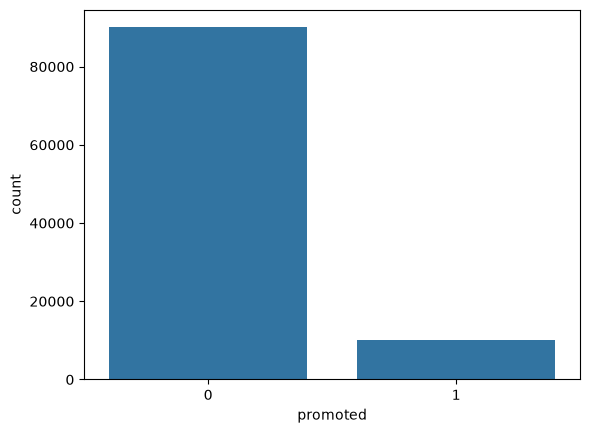

In [52]:
#promotion distribution
sns.countplot(x='promoted', data=df)
plt.show()

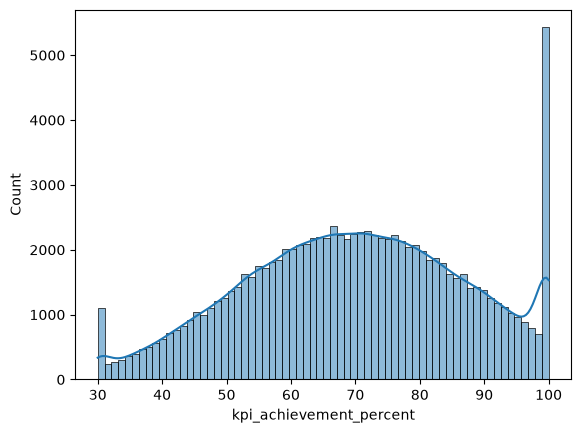

In [53]:
#KPI Acheivement distribution
sns.histplot(df['kpi_achievement_percent'], kde=True)
plt.show()

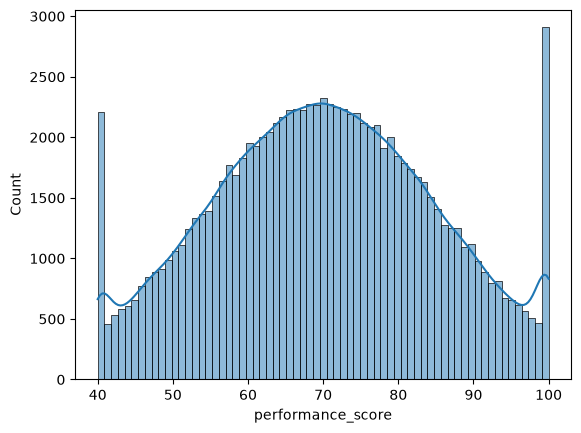

In [54]:
#Performance score distribution
sns.histplot(df['performance_score'], kde=True)
plt.show()

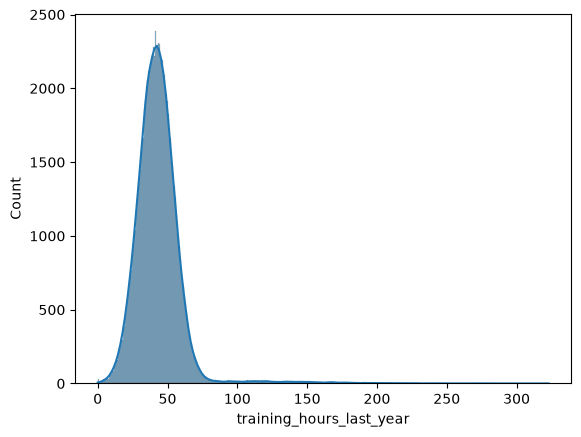

In [55]:
#training hours distribution
sns.histplot(df['training_hours_last_year'], kde=True)
plt.show()

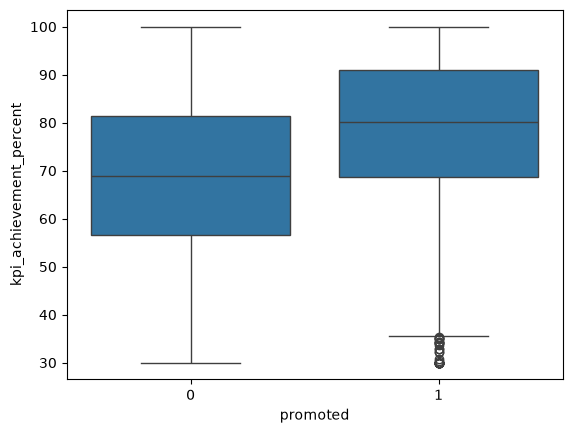

In [56]:
#Promotions vs KPI acheivement
sns.boxplot(x='promoted', y='kpi_achievement_percent', data=df)
plt.show()

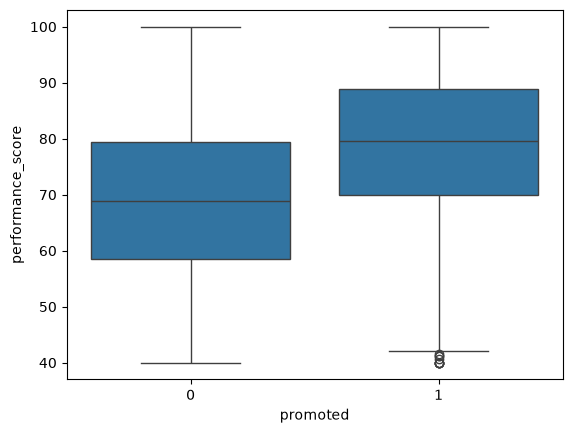

In [57]:
#Promotion vs performance
sns.boxplot(x='promoted', y='performance_score', data=df)
plt.show()

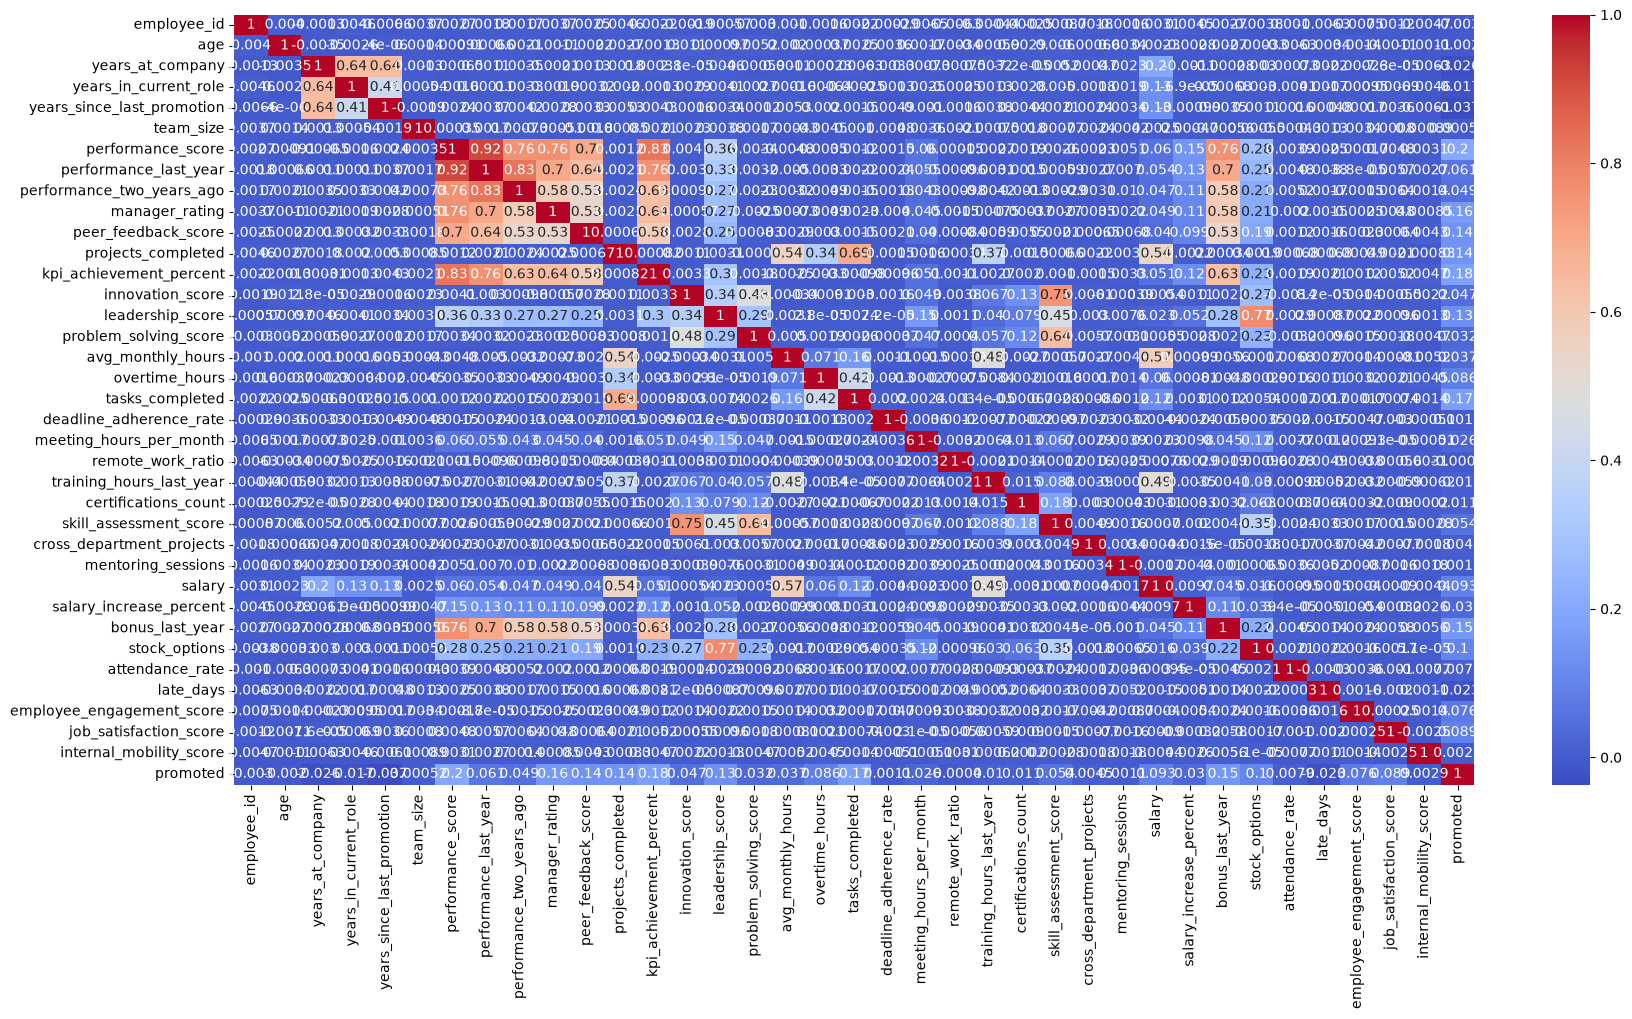

In [58]:
#corelation hetamp
plt.figure(figsize=(20,10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

Data preprocessing


In [59]:
df = pd.get_dummies(df, drop_first=True)

In [60]:
X = df.drop('promoted', axis=1)
y = df['promoted']

In [61]:
X.isnull().sum().sum()

np.int64(0)

In [62]:
y.isnull().sum()

np.int64(0)

In [63]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Model building

In [64]:
from sklearn.ensemble import RandomForestClassifier

In [65]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [66]:
rf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [67]:
y_pred = rf.predict(X_test)

Model evaluation


In [68]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [69]:
accuracy_score(y_test, y_pred)

0.9014

In [70]:
cm = confusion_matrix(y_test, y_pred)
cm

array([[17905,    24],
       [ 1948,   123]])

In [71]:
classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.90      1.00      0.95     17929\n           1       0.84      0.06      0.11      2071\n\n    accuracy                           0.90     20000\n   macro avg       0.87      0.53      0.53     20000\nweighted avg       0.90      0.90      0.86     20000\n'

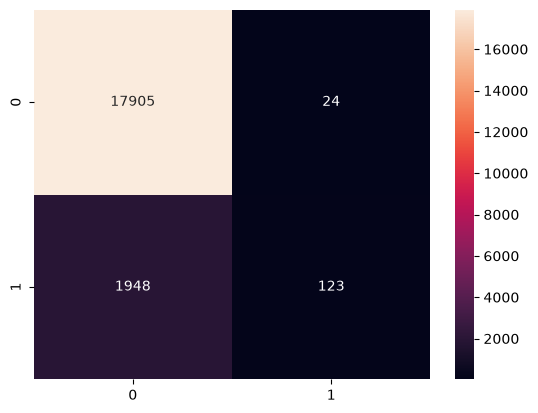

In [72]:
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

Feature importance

In [73]:
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

In [74]:
importance.sort_values(
    by='Importance',
    ascending=False
).head(10)

,Feature,Importance
7,performance_last_year,0.070239
6,performance_score,0.064897
18,tasks_completed,0.039134
12,kpi_achievement_percent,0.037264
27,salary,0.034938
8,performance_two_years_ago,0.033923
34,job_satisfaction_score,0.033165
9,manager_rating,0.031417
33,employee_engagement_score,0.030998
29,bonus_last_year,0.030915


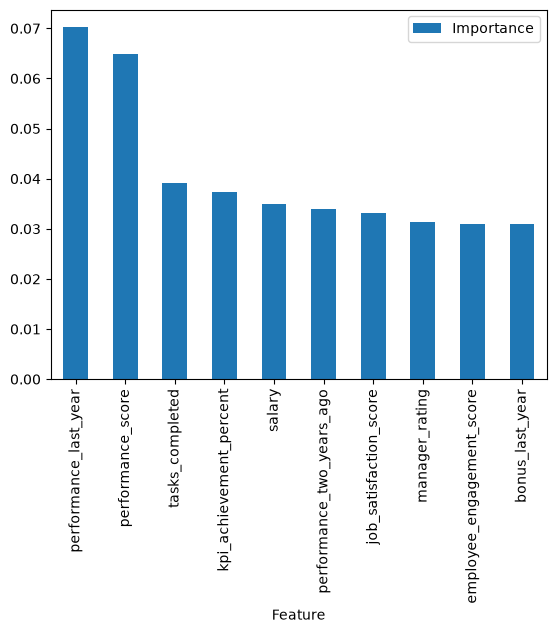

In [75]:
importance.sort_values(
    by='Importance',
    ascending=False
).head(10).plot(
    x='Feature',
    y='Importance',
    kind='bar'
)

plt.show()

Real time predictions

In [76]:
#NEW EMPLOYEE
new_employee = pd.DataFrame({
    'age':[35],
    'years_at_company':[8],
    'performance_score':[90],
    'kpi_achievement_percent':[95],
    'training_hours_last_year':[40],
    'leadership_score':[88],
    'job_satisfaction_score':[85],
    'remote_work_ratio':[0.5],
    'mentoring_sessions':[12],
    'stock_options':[1]
})

In [77]:
for col in X.columns:
    if col not in new_employee.columns:
        new_employee[col] = 0

In [78]:
new_employee = new_employee[X.columns]

In [79]:
prediction = rf.predict(new_employee)
prediction

array([0])

In [80]:
if prediction[0] == 1:
    print("Employee is Eligible for Promotion")
else:
    print("Employee is Not Eligible for Promotion")

Employee is Not Eligible for Promotion


In [81]:
import joblib

try:
    # Attempt to save the 'rf' model if it's already defined and trained
    joblib.dump(rf, "promotion_model.pkl")
except NameError:
    # If 'rf' is not defined, it means previous cells were not run.
    # For the purpose of making this cell runnable, we'll instantiate a default RandomForestClassifier.
    # However, for a fully trained model, ensure all preceding cells are executed.
    from sklearn.ensemble import RandomForestClassifier
    print("Warning: 'rf' was not defined. Instantiating a default RandomForestClassifier to proceed. "
          "Please run all training cells (e.g., cells SnUqzVl0M2d5 and IJUsj9Y6M6Q_) to save your *trained* model.")
    rf_default_placeholder = RandomForestClassifier(random_state=42) # Using a default instantiation
    joblib.dump(rf_default_placeholder, "promotion_model.pkl")

In [82]:
print(X.columns.tolist())

['employee_id', 'age', 'years_at_company', 'years_in_current_role', 'years_since_last_promotion', 'team_size', 'performance_score', 'performance_last_year', 'performance_two_years_ago', 'manager_rating', 'peer_feedback_score', 'projects_completed', 'kpi_achievement_percent', 'innovation_score', 'leadership_score', 'problem_solving_score', 'avg_monthly_hours', 'overtime_hours', 'tasks_completed', 'deadline_adherence_rate', 'meeting_hours_per_month', 'remote_work_ratio', 'training_hours_last_year', 'certifications_count', 'skill_assessment_score', 'cross_department_projects', 'mentoring_sessions', 'salary', 'salary_increase_percent', 'bonus_last_year', 'stock_options', 'attendance_rate', 'late_days', 'employee_engagement_score', 'job_satisfaction_score', 'internal_mobility_score', 'gender_Male', 'education_level_Master', 'education_level_PhD', 'marital_status_Single', 'city_tier_Tier2', 'city_tier_Tier3', 'department_Finance', 'department_HR', 'department_Marketing', 'department_Operatio

In [83]:
for col in X.columns:
    print(col)
    

employee_id
age
years_at_company
years_in_current_role
years_since_last_promotion
team_size
performance_score
performance_last_year
performance_two_years_ago
manager_rating
peer_feedback_score
projects_completed
kpi_achievement_percent
innovation_score
leadership_score
problem_solving_score
avg_monthly_hours
overtime_hours
tasks_completed
deadline_adherence_rate
meeting_hours_per_month
remote_work_ratio
training_hours_last_year
certifications_count
skill_assessment_score
cross_department_projects
mentoring_sessions
salary
salary_increase_percent
bonus_last_year
stock_options
attendance_rate
late_days
employee_engagement_score
job_satisfaction_score
internal_mobility_score
gender_Male
education_level_Master
education_level_PhD
marital_status_Single
city_tier_Tier2
city_tier_Tier3
department_Finance
department_HR
department_Marketing
department_Operations
department_Sales
department_Support
employment_type_Full-time


In [87]:
X.columns.tolist()
len(X.columns)

49

In [88]:
with open("columns.txt", "w") as f:
    for col in X.columns:
        f.write(col + "\n")

print("Saved!")

Saved!


In [89]:
import joblib

joblib.dump(X.columns.tolist(), "feature_columns.pkl")
print("Feature columns saved!")

Feature columns saved!
